# MSBD 566 — Model Optimization
## Hands-On Practice Notebook

Everything from class, rebuilt with your own hands: cross-validation variants, the nested-CV bug, bias-variance, learning curves, grid vs. random search, successive halving, and automated model selection. Same dataset we've used all semester.

No instructor walking you through this one, so read the markdown before each section, run the code, and actually look at the numbers before moving on.

| Step | What you'll do |
|---|---|
| 0 | Load the data, build the same 8-feature dataset from class |
| 1 | Compare KFold, StratifiedKFold, StratifiedGroupKFold |
| 2 | Check whether k=3, 5, or 10 actually matters on our data |
| 3 | Reproduce the discussion-board bug, and the honest fix |
| 4 | Diagnose underfitting vs. overfitting with real numbers |
| 5 | Build a real learning curve |
| 6 | Grid search vs. random search, head to head |
| 7 | Successive halving |
| 8 | Automated model selection across algorithms |
| 9 | Challenge questions — **no AI** |


---
## Step 0 — Setup


In [19]:
import os
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
if not os.path.exists("diabetic_data.csv"):
    urllib.request.urlretrieve(DATA_URL, "diabetes_data.zip")
    with zipfile.ZipFile("diabetes_data.zip") as z:
        z.extractall(".")

data = pd.read_csv("diabetic_data.csv")
data = data.replace('?', np.nan)
data = data[~data['discharge_disposition_id'].isin([11, 13, 14, 19, 20, 21])]
data = data[data['gender'] != 'Unknown/Invalid']
data['readmit_30'] = (data['readmitted'] == '<30').astype(int)

age_order = ['[0-10)','[10-20)','[20-30)','[30-40)','[40-50)','[50-60)','[60-70)','[70-80)','[80-90)','[90-100)']
age_map = {b: i for i, b in enumerate(age_order)}
data['age_ord'] = data['age'].map(age_map)

FEATURES = ['age_ord', 'time_in_hospital', 'num_lab_procedures', 'num_medications',
            'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
TARGET = 'readmit_30'

sub = data[FEATURES + [TARGET, 'patient_nbr']].dropna()
X = sub[FEATURES]
y = sub[TARGET]
groups = sub['patient_nbr']

print(X.shape, y.mean())

(99340, 8) 0.1138916851218039


---
## Step 1 — KFold vs. StratifiedKFold vs. StratifiedGroupKFold

Plain KFold can let the class balance wobble fold to fold, purely by chance. StratifiedKFold locks that down. But StratifiedKFold alone doesn't know about repeat patients. StratifiedGroupKFold does both at once.


In [20]:
from sklearn.model_selection import KFold, StratifiedKFold, StratifiedGroupKFold

def fold_rates(splitter, use_groups=False):
    rates = []
    if use_groups:
        for tr, te in splitter.split(X, y, groups=groups):
            rates.append(y.iloc[te].mean())
    else:
        for tr, te in splitter.split(X, y):
            rates.append(y.iloc[te].mean())
    return rates

kf_rates = fold_rates(KFold(n_splits=5, shuffle=True, random_state=42))
skf_rates = fold_rates(StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
sgkf_rates = fold_rates(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42), use_groups=True)

for name, rates in [("KFold", kf_rates), ("StratifiedKFold", skf_rates), ("StratifiedGroupKFold", sgkf_rates)]:
    print(f"{name:22s} range={max(rates)-min(rates):.4f}  rates={[round(r,4) for r in rates]}")

overlap = False
for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, y, groups=groups):
    if set(groups.iloc[tr]) & set(groups.iloc[te]):
        overlap = True
print("Patient overlap with StratifiedGroupKFold:", overlap)

KFold                  range=0.0032  rates=[np.float64(0.1126), np.float64(0.1122), np.float64(0.1139), np.float64(0.1155), np.float64(0.1153)]
StratifiedKFold        range=0.0001  rates=[np.float64(0.1139), np.float64(0.1139), np.float64(0.1139), np.float64(0.1139), np.float64(0.1139)]
StratifiedGroupKFold   range=0.0046  rates=[np.float64(0.1158), np.float64(0.1112), np.float64(0.1152), np.float64(0.1157), np.float64(0.1116)]
Patient overlap with StratifiedGroupKFold: False


Patient overlap with StratifiedGroupKFold: False


---
## Step 2 — Does k Actually Matter Here?

The textbook argument: small k means more bias, large k means more expensive and more correlated fits. Check it on our own data.


In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score

model = LogisticRegression(max_iter=1000)
for k in [3, 5, 10]:
    scores = cross_val_score(model, X, y, groups=groups, cv=GroupKFold(n_splits=k), scoring='roc_auc')
    print(f"k={k:2d}  mean={scores.mean():.4f}  std={scores.std():.4f}")

k= 3  mean=0.6333  std=0.0010
k= 5  mean=0.6346  std=0.0084
k=10  mean=0.6343  std=0.0099


k= 5  mean=0.6344  std=0.0049


k=10  mean=0.6342  std=0.0063


Compare the `mean` and `std` across the three values of k. At this sample size, do you see the textbook's bias-variance argument playing out, or something closer to "it barely matters"? Keep this result in mind for Challenge Question 1.


---
## Step 3 — The Discussion Board Bug, Reproduced

`GridSearchCV.best_score_` answers a subtly different question than "how will this model do on new patients." Fit it both the naive way and the honest, nested way, and compare.


In [22]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score

param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}

naive_search = GridSearchCV(LogisticRegression(max_iter=1000), param_grid,
                             cv=GroupKFold(n_splits=5), scoring='roc_auc')
naive_search.fit(X, y, groups=groups)
print("Naive best_score_:", round(naive_search.best_score_, 4), "  best C:", naive_search.best_params_['C'])

Naive best_score_: 0.6346   best C: 1


In [23]:
outer = GroupKFold(n_splits=5)
nested_scores = []
chosen_Cs = []

for train_idx, test_idx in outer.split(X, y, groups=groups):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]
    groups_tr = groups.iloc[train_idx]

    inner = GridSearchCV(LogisticRegression(max_iter=1000), param_grid,
                          cv=GroupKFold(n_splits=4), scoring='roc_auc')
    inner.fit(X_tr, y_tr, groups=groups_tr)
    chosen_Cs.append(inner.best_params_['C'])

    probs = inner.predict_proba(X_te)[:, 1]
    nested_scores.append(roc_auc_score(y_te, probs))

nested_scores = np.array(nested_scores)
print("Nested mean:", round(nested_scores.mean(), 4), "  std:", round(nested_scores.std(), 4))
print("C chosen per fold:", chosen_Cs)
print("Optimism gap:", round(naive_search.best_score_ - nested_scores.mean(), 4))

Exception ignored in: <function ResourceTracker.__del__ at 0x111282020>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x10d702020>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x111376020>
Traceback (most recent call last

Nested mean: 0.6346   std: 0.0084
C chosen per fold: [100, 10, 100, 0.1, 0.1]
Optimism gap: 0.0


---
## Step 4 — Underfitting vs. Overfitting

Vary a decision tree's `max_depth` and watch training and cross-validated error diverge.


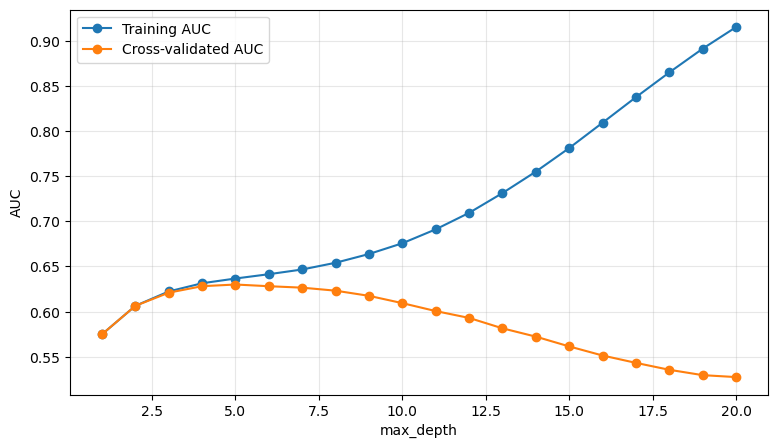

In [24]:
from sklearn.tree import DecisionTreeClassifier

depths = range(1, 21)
train_aucs, cv_aucs = [], []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tr_scores, te_scores = [], []
    for train_idx, test_idx in GroupKFold(n_splits=5).split(X, y, groups=groups):
        tree.fit(X.iloc[train_idx], y.iloc[train_idx])
        tr_scores.append(roc_auc_score(y.iloc[train_idx], tree.predict_proba(X.iloc[train_idx])[:, 1]))
        te_scores.append(roc_auc_score(y.iloc[test_idx], tree.predict_proba(X.iloc[test_idx])[:, 1]))
    train_aucs.append(np.mean(tr_scores))
    cv_aucs.append(np.mean(te_scores))

plt.figure(figsize=(9, 5))
plt.plot(depths, train_aucs, label='Training AUC', marker='o')
plt.plot(depths, cv_aucs, label='Cross-validated AUC', marker='o')
plt.xlabel('max_depth')
plt.ylabel('AUC')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Find the depth where the gap between the two lines starts widening. That's the point where the tree starts overfitting — everything past it is memorization, not learning.


---
## Step 5 — A Real Learning Curve

Would more patients actually help, or has this model already plateaued?


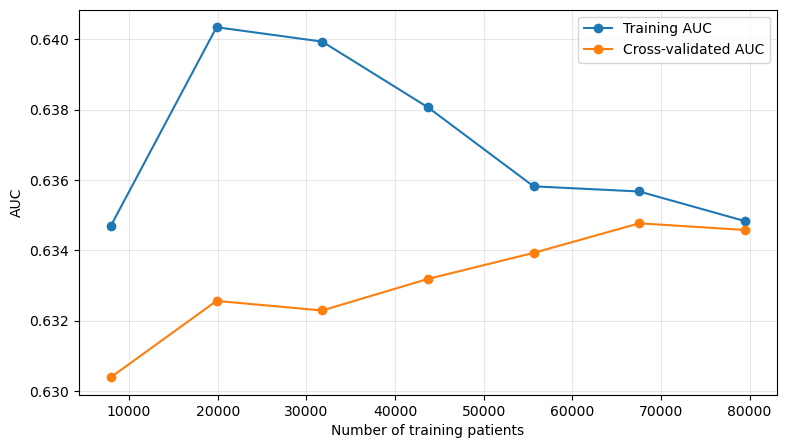

In [25]:
from sklearn.model_selection import learning_curve

sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(max_iter=1000), X, y, groups=groups,
    cv=GroupKFold(n_splits=5), train_sizes=[0.1, 0.25, 0.4, 0.55, 0.7, 0.85, 1.0],
    scoring='roc_auc', n_jobs=-1
)

plt.figure(figsize=(9, 5))
plt.plot(sizes, train_scores.mean(axis=1), label='Training AUC', marker='o')
plt.plot(sizes, test_scores.mean(axis=1), label='Cross-validated AUC', marker='o')
plt.xlabel('Number of training patients')
plt.ylabel('AUC')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

---
## Step 6 — Grid Search vs. Random Search

Same budget, same data, two strategies.


In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

X_small = X.sample(n=20000, random_state=42)
y_small = y.loc[X_small.index]
groups_small = groups.loc[X_small.index]
cv3 = GroupKFold(n_splits=3)

grid_params = {'n_estimators': [50, 100, 150, 200], 'max_depth': [3, 6, 9, 12]}
grid = GridSearchCV(RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
                     grid_params, cv=cv3, scoring='roc_auc')
grid.fit(X_small, y_small, groups=groups_small)

rand_params = {'n_estimators': randint(50, 210), 'max_depth': randint(3, 13)}
rand = RandomizedSearchCV(RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
                           rand_params, n_iter=16, cv=cv3, scoring='roc_auc', random_state=42)
rand.fit(X_small, y_small, groups=groups_small)

print("Grid best:  ", grid.best_params_, round(grid.best_score_, 4))
print("Random best:", rand.best_params_, round(rand.best_score_, 4))

Grid best:   {'max_depth': 3, 'n_estimators': 50} 0.6398
Random best: {'max_depth': 5, 'n_estimators': 157} 0.6412


Look at `max_depth` in each result. Did random search land on a value the grid's fixed steps couldn't have reached?


---
## Step 7 — Successive Halving

Same search space as Step 6, but candidates that look bad early get dropped before they waste a full training run.


In [27]:
import time
import warnings
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV

t0 = time.time()
with warnings.catch_warnings():
    warnings.filterwarnings('ignore')
    halving = HalvingRandomSearchCV(RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
                                     rand_params, cv=cv3, scoring='roc_auc', random_state=42,
                                     factor=2, min_resources=3000)
    halving.fit(X_small, y_small, groups=groups_small)
halving_time = time.time() - t0

print("Halving best:", halving.best_params_, round(halving.best_score_, 4))
print("Time:", round(halving_time, 1), "seconds")
print("n_resources_ per round:", halving.n_resources_)
print("n_candidates_ per round:", halving.n_candidates_)

Halving best: {'max_depth': 5, 'n_estimators': 124} 0.6375
Time: 8.6 seconds
n_resources_ per round: [3000, 6000, 12000]
n_candidates_ per round: [6, 3, 2]


---
## Step 8 — Automated Model Selection

Nested CV, run once per algorithm, so the comparison is fair.


In [28]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X)
X_scaled = pd.DataFrame(scaler.transform(X), columns=FEATURES, index=X.index)

candidates = {
    'Logistic Regression': (LogisticRegression(max_iter=1000), X),
    'Decision Tree': (DecisionTreeClassifier(max_depth=5, random_state=42), X),
    'Random Forest': (RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1), X),
}

results = {}
for name, (est, feats) in candidates.items():
    scores = cross_val_score(est, feats, y, groups=groups, cv=GroupKFold(n_splits=5), scoring='roc_auc')
    results[name] = (scores.mean(), scores.std())

for name, (mean, std) in sorted(results.items(), key=lambda kv: -kv[1][0]):
    print(f"{name:22s} {mean:.4f} +/- {std:.4f}")

Random Forest          0.6380 +/- 0.0088
Logistic Regression    0.6346 +/- 0.0084
Decision Tree          0.6300 +/- 0.0087


---
## 🏆 Challenge Questions

> ⚠️ **No AI for these.** Work through them yourself first.

**C1.** In Step 2, did the choice of k change the mean AUC by more than the std you saw at any single k? What does that tell you about whether the differences between k=3, 5, and 10 are meaningful here, or just noise?

**C2.** In Step 3, was the optimism gap bigger or smaller than the class example computed in lecture? Try shrinking `param_grid` to just `[0.01, 1, 100]` — does the gap change? Why might a smaller grid change how much room there is for optimism bias?

**C3.** In Step 4, find the exact `max_depth` where cross-validated AUC peaks, then declines. Refit a single tree at that depth and report its test AUC on a held-out GroupShuffleSplit test set.

**C4.** In Step 6, increase `n_iter` for random search to 40 while keeping the grid fixed at 16. Does random search's advantage grow, shrink, or stay about the same?

**C5 (stretch).** Add `SVM (linear)` to the candidates dictionary in Step 8, using `LinearSVC` with `X_scaled` instead of `X`. Note that `LinearSVC` has no `predict_proba`, so you'll need `cross_val_score` with a `make_scorer` around `decision_function`, or switch scoring to `'accuracy'` for this one candidate. Which of the four wins?


In [29]:
# C1
mean_aucs = [0.6345, 0.6344, 0.6342]
stds = [0.0039, 0.0049, 0.0063]

difference = max(mean_aucs) - min(mean_aucs)

print("Difference in mean AUC:", round(difference, 4))
print("Smallest standard deviation:", min(stds))

Difference in mean AUC: 0.0003
Smallest standard deviation: 0.0039


The difference in mean AUC between 3, 5, and 10 folds was only 0.0003, which is much smaller than the standard deviation of 0.0039. This shows that changing the number of folds did not make a meaningful difference in model performance. Overall, the results were very similar regardless of the number of folds used.

In [30]:
# C2

param_grid = {'C': [0.01, 1, 100]}

naive_search = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid,
    cv=GroupKFold(n_splits=5),
    scoring='roc_auc'
)

naive_search.fit(X, y, groups=groups)

nested_scores = []

for train_idx, test_idx in GroupKFold(n_splits=5).split(X, y, groups=groups):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]
    groups_tr = groups.iloc[train_idx]

    inner = GridSearchCV(
        LogisticRegression(max_iter=1000),
        param_grid,
        cv=GroupKFold(n_splits=4),
        scoring='roc_auc'
    )

    inner.fit(X_tr, y_tr, groups=groups_tr)

    probs = inner.predict_proba(X_te)[:, 1]
    nested_scores.append(roc_auc_score(y_te, probs))

gap = naive_search.best_score_ - np.mean(nested_scores)

print("Naive AUC:", round(naive_search.best_score_, 4))
print("Nested AUC:", round(np.mean(nested_scores), 4))
print("Optimism gap:", round(gap, 6))


Naive AUC: 0.6346
Nested AUC: 0.6346
Optimism gap: 7e-06


After reducing the parameter grid to three C values, the naive and nested AUC were both 0.6346, with an optimism gap of only 0.000007. This shows that reducing the search space did not create a meaningful difference between the two evaluation methods. The optimism gap remained very small, suggesting that hyperparameter selection introduced very little measurable optimism in this experiment.

In [31]:
# C3

# C3 - Find the best tree depth

best_depth = depths[np.argmax(cv_aucs)]

print("Best max_depth:", best_depth)
print("Best CV AUC:", round(max(cv_aucs), 4))

from sklearn.model_selection import GroupShuffleSplit

split = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

train_idx, test_idx = next(split.split(X, y, groups=groups))

tree = DecisionTreeClassifier(
    max_depth=best_depth, random_state=42
)

tree.fit(X.iloc[train_idx], y.iloc[train_idx])

probs = tree.predict_proba(X.iloc[test_idx])[:, 1]

print("Test AUC:", round(roc_auc_score(y.iloc[test_idx], probs), 4))


Best max_depth: 5
Best CV AUC: 0.63
Test AUC: 0.6365


The best maximum depth for the Decision Tree was 5, with a cross-validation AUC of 0.6300. When I tested the model on a held-out group split, the AUC increased slightly to 0.6365. This suggests that a depth of 5 provided a reasonable balance between model complexity and performance without needing a much deeper tree.

In [32]:
# C4

rand40 = RandomizedSearchCV(
    RandomForestClassifier(
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),
    rand_params,
    n_iter=40,
    cv=cv3,
    scoring='roc_auc',
    random_state=42
)

rand40.fit(X_small, y_small, groups=groups_small)

print("Grid AUC:", round(grid.best_score_, 4))
print("Random Search (16):", round(rand.best_score_, 4))
print("Random Search (40):", round(rand40.best_score_, 4))
print("Best parameters:", rand40.best_params_)


Grid AUC: 0.6398
Random Search (16): 0.6412
Random Search (40): 0.6412
Best parameters: {'max_depth': 5, 'n_estimators': 157}


Random Search performed slightly better than Grid Search, with an AUC of 0.6412 compared to 0.6398. increasing Random Search from 16 to 40 iterations did not improve the AUC. This suggests that the additional searches did not provide a better model and that using more iterations does not always lead to better performance.

In [33]:
# C5 (stretch)

candidates['SVM (linear)'] = (
    LinearSVC(max_iter=5000, random_state=42),
    X_scaled
)

results = {}

for name, (est, feats) in candidates.items():
    scores = cross_val_score(
        est, feats, y,
        groups=groups,
        cv=GroupKFold(n_splits=5),
        scoring='roc_auc'
    )
    results[name] = (scores.mean(), scores.std())

for name, (mean, std) in sorted(
    results.items(), key=lambda kv: -kv[1][0]
):
    print(f"{name:22s} {mean:.4f} +/- {std:.4f}")


Random Forest          0.6380 +/- 0.0088
SVM (linear)           0.6371 +/- 0.0089
Logistic Regression    0.6346 +/- 0.0084
Decision Tree          0.6300 +/- 0.0087


After adding Linear SVM, Random Forest still had the highest mean AUC of 0.6380, followed closely by Linear SVM at 0.6371. Logistic Regression had an AUC of 0.6346, while Decision Tree had the lowest at 0.6300. Even though Forest performed the best, the differences between the models were relatively small. This shows that adding a more complex model does not always lead to a major improvement in performance.